#Section 1: Processing data
## Section 1.1: First get the unprocessed data from zip file


In [1]:
import zipfile
from pathlib import Path
import torch
from torch import nn

import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt


In [2]:
# Setup path to a data folder for audio
data_path = Path("data/")
audio_path = data_path / "audio_data" # Renaming image_path to audio_path for clarity

# Setup path to a data folder for labels
label_path = data_path / "label"

# Create audio data directory if it doesn't exist
if audio_path.is_dir():
  print(f"{audio_path} directory already exists... skipping creation")
else:
  print(f"{audio_path} does not exist, creating one...")
  audio_path.mkdir(parents=True, exist_ok=True)

# Create label directory if it doesn't exist
if label_path.is_dir():
  print(f"{label_path} directory already exists... skipping creation")
else:
  print(f"{label_path} does not exist, creating one...")
  label_path.mkdir(parents=True, exist_ok=True)

# Unzip the specified zip files
zip_files_to_extract = {
    "annotation.zip": label_path,
    "audio_mono-pickup_mix.zip": audio_path
}

for zip_file_name, extract_path in zip_files_to_extract.items():
  if Path(zip_file_name).is_file():
    with zipfile.ZipFile(zip_file_name, "r") as zip_ref:
      print(f"Unzipping {zip_file_name} to {extract_path}...")
      zip_ref.extractall(extract_path)
  else:
    print(f"Warning: {zip_file_name} not found. Skipping extraction.")

data\audio_data directory already exists... skipping creation
data\label directory already exists... skipping creation
Unzipping annotation.zip to data\label...
Unzipping audio_mono-pickup_mix.zip to data\audio_data...


##Section 1.2: Load guitarset annotation (JAMS file)

In [3]:
!pip install jams

In [11]:
import jams
import numpy as np

# Standard guitar open string MIDI pitches (E2, A2, D3, G3, B3, E4)
OPEN_STRING_MIDI = [40, 45, 50, 55, 59, 64]
N_FRETS = 21  # 0-19 + muted

def get_labels_for_file(jams_path, n_frames, hop_length=512, sr=22050):
    jam = jams.load(str(jams_path))

    frame_times = np.arange(n_frames) * hop_length / sr
    labels = np.full((n_frames, 6), 20, dtype=np.int64)  # 20 = muted

    # Get all note_midi annotations, one per string (data_source 0-5)
    note_midi_anns = [ann for ann in jam.annotations if ann.namespace == 'note_midi']

    for string_idx, ann in enumerate(note_midi_anns):
        for obs in ann.data:
            onset = obs.time          # float, seconds
            duration = obs.duration   # float, seconds
            offset = onset + duration
            midi_note = obs.value     # float, round to nearest int

            fret = int(round(midi_note)) - OPEN_STRING_MIDI[string_idx]

            if 0 <= fret <= 19:
                frame_mask = (frame_times >= onset) & (frame_times < offset)
                labels[frame_mask, string_idx] = fret

    return labels

##Section 1.3: Extract sliding windows from CQT

In [4]:
def extract_windows(cqt_db, window_size=9):
    pad = window_size // 2
    cqt_padded = np.pad(cqt_db, ((0, 0), (pad, pad)), mode='constant')
    windows = []
    for i in range(cqt_db.shape[1]):
        window = cqt_padded[:, i:i+window_size]
        windows.append(window)
    return np.array(windows)  # (n_frames, 192, 9)

##Section 1.4: Downsample and normalize audio, then extract sliding window from CQT, and get labels



In [5]:
from pathlib import Path
import librosa
import soundfile as sf
from scipy.signal import resample_poly
from torch.utils.data import Dataset, DataLoader, random_split
import torch
import jams
import numpy as np

In [7]:


audio_dir = Path("data/audio_data")
annot_dir = Path("data/label")  # adjust to your path


all_windows = []
all_labels = []


for wav_path in audio_dir.glob("*.wav"):
    jams_path = annot_dir / (wav_path.stem.replace("_mix", "") + ".jams")
    if not jams_path.exists():
        print(f"No annotation found for {wav_path.name}, skipping")
        continue

    # Audio preprocessing
    audio_np, sr = sf.read(str(wav_path), always_2d=True)
    audio_np = audio_np.mean(axis=1)  # stereo to mono

    # Resample from 44100 to 22050 (factor of 2)
    audio_np = resample_poly(audio_np, up=1, down=2)

    # Normalize
    max_val = np.abs(audio_np).max()
    if max_val > 0:
        audio_np = audio_np / max_val

    # CQT
    cqt = librosa.cqt(audio_np, sr=22050, hop_length=512,
                      fmin=librosa.note_to_hz('C1'),
                      n_bins=192, bins_per_octave=24)
    cqt_db = librosa.amplitude_to_db(np.abs(cqt), ref=np.max)

    # Sliding windows
    windows = extract_windows(cqt_db)  # (n_frames, 192, 9)
    n_frames = windows.shape[0]

    # Labels
    labels = get_labels_for_file(jams_path, n_frames)  # (n_frames, 6)

    all_windows.append(windows)
    all_labels.append(labels)
    print(f"Processed {wav_path.name}: {windows.shape}, {labels.shape}")

# Combine everything
all_windows = np.concatenate(all_windows, axis=0)  # (total_frames, 192, 9)
all_labels = np.concatenate(all_labels, axis=0)    # (total_frames, 6)

print(f"\nFinal dataset: {all_windows.shape}, {all_labels.shape}")
np.save("all_windows.npy", all_windows)
np.save("all_labels.npy", all_labels)
print("Saved!")

Processed 00_BN1-129-Eb_comp_mix.wav: (962, 192, 9), (962, 6)
Processed 00_BN1-129-Eb_solo_mix.wav: (962, 192, 9), (962, 6)
Processed 00_BN1-147-Gb_comp_mix.wav: (844, 192, 9), (844, 6)
Processed 00_BN1-147-Gb_solo_mix.wav: (844, 192, 9), (844, 6)
Processed 00_BN2-131-B_comp_mix.wav: (1263, 192, 9), (1263, 6)
Processed 00_BN2-131-B_solo_mix.wav: (1263, 192, 9), (1263, 6)
Processed 00_BN2-166-Ab_comp_mix.wav: (997, 192, 9), (997, 6)
Processed 00_BN2-166-Ab_solo_mix.wav: (997, 192, 9), (997, 6)
Processed 00_BN3-119-G_comp_mix.wav: (1390, 192, 9), (1390, 6)
Processed 00_BN3-119-G_solo_mix.wav: (1390, 192, 9), (1390, 6)
Processed 00_BN3-154-E_comp_mix.wav: (1074, 192, 9), (1074, 6)
Processed 00_BN3-154-E_solo_mix.wav: (1074, 192, 9), (1074, 6)
Processed 00_Funk1-114-Ab_comp_mix.wav: (1088, 192, 9), (1088, 6)
Processed 00_Funk1-114-Ab_solo_mix.wav: (1088, 192, 9), (1088, 6)
Processed 00_Funk1-97-C_comp_mix.wav: (1279, 192, 9), (1279, 6)
Processed 00_Funk1-97-C_solo_mix.wav: (1279, 192, 9), 

In [6]:
import numpy as np
from pathlib import Path

windows_path = Path("all_windows.npy")
labels_path  = Path("all_labels.npy")


all_windows = np.load("all_windows.npy")
all_labels  = np.load("all_labels.npy")
print(f"Loaded from disk: {all_windows.shape}, {all_labels.shape}")


Loaded from disk: (472560, 192, 9), (472560, 6)


In [7]:
from torch.utils.data import Dataset, DataLoader, random_split
import torch

class GuitarSetDataset(Dataset):
    def __init__(self, windows, labels):
        self.windows = torch.tensor(windows, dtype=torch.float32).unsqueeze(1)  # (N, 1, 192, 9)
        self.labels = torch.tensor(labels, dtype=torch.long)                    # (N, 6)

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        return self.windows[idx], self.labels[idx]

full_dataset = GuitarSetDataset(all_windows, all_labels)

# 80/10/10 split
total = len(full_dataset)
train_size = int(0.8 * total)
val_size   = int(0.1 * total)
test_size  = total - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(full_dataset, [train_size, val_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False)

print(f"Train: {train_size}, Val: {val_size}, Test: {test_size}")

# Verify shapes
x, y = next(iter(train_loader))
print(f"Input: {x.shape}")  # (128, 1, 192, 9)
print(f"Labels: {y.shape}") # (128, 6)

Train: 378048, Val: 47256, Test: 47256
Input: torch.Size([128, 1, 192, 9])
Labels: torch.Size([128, 6])


##Section 1.5: Visualize


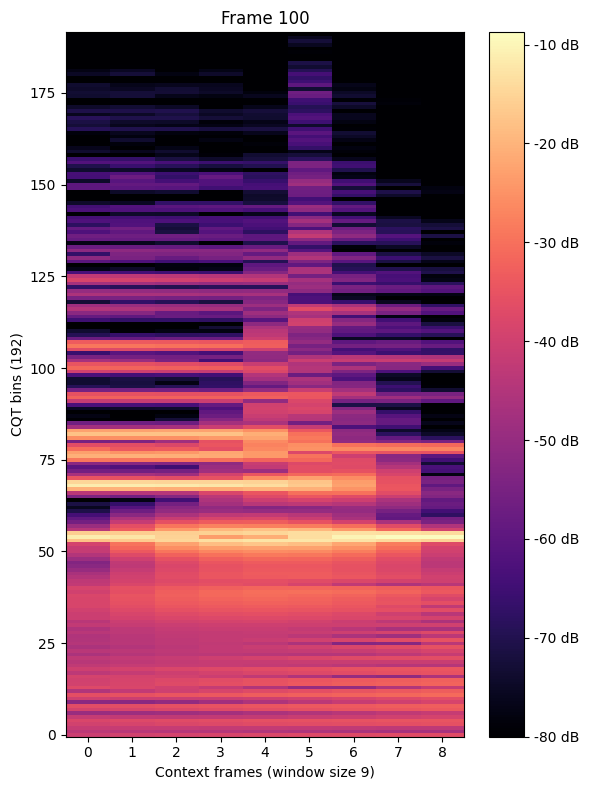

Label for frame 100: [20  6  8  7  6 20]


In [10]:
frame_idx = 100  # any frame number

window = all_windows[frame_idx]  # shape (192, 9)

plt.figure(figsize=(6, 8))
plt.imshow(window, aspect='auto', origin='lower', cmap='magma')
plt.colorbar(format="%+2.0f dB")
plt.xlabel("Context frames (window size 9)")
plt.ylabel("CQT bins (192)")
plt.title(f"Frame {frame_idx}")
plt.tight_layout()
plt.show()
print(f"Label for frame {frame_idx}: {all_labels[frame_idx]}")

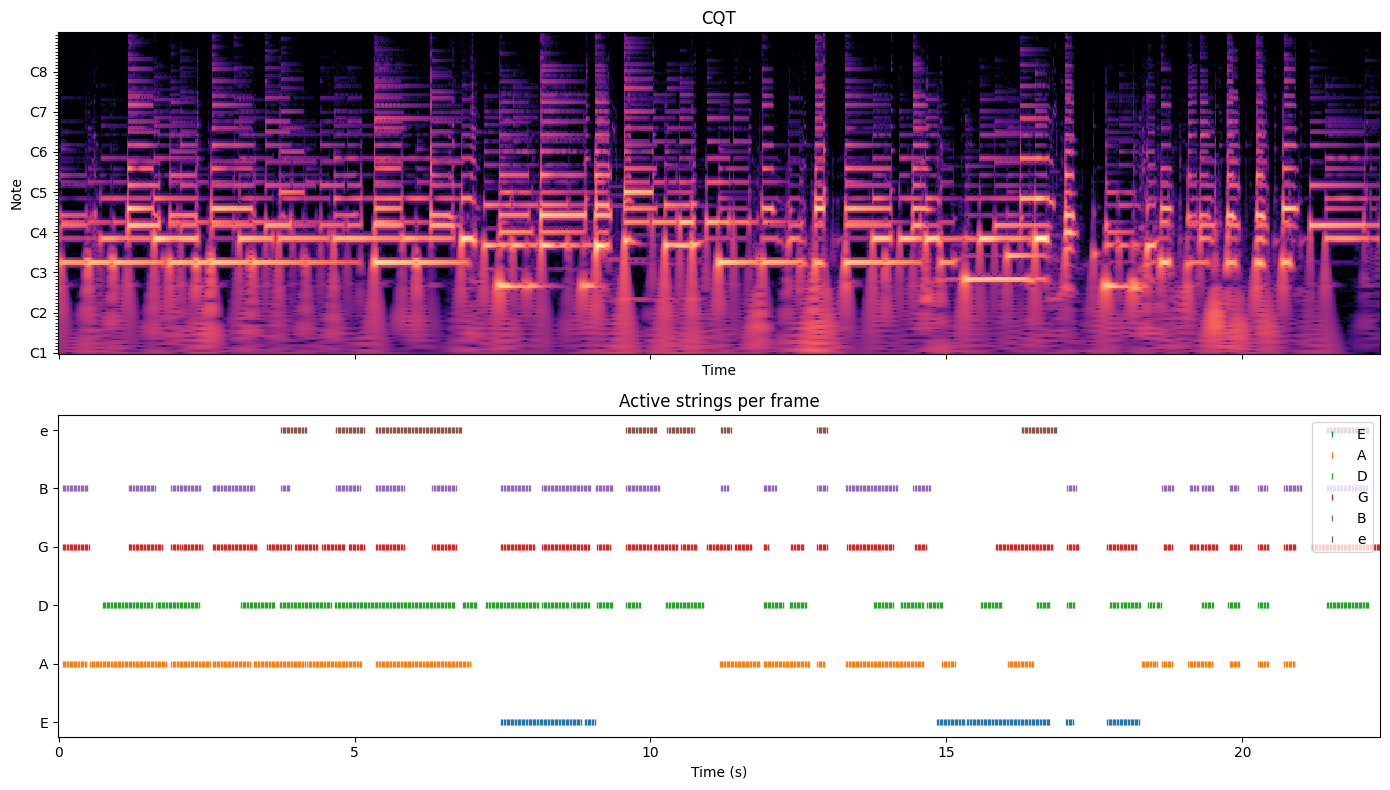

In [22]:
# Reprocess one file to verify
wav_path = Path("data/audio_data/00_BN1-129-Eb_comp_mix.wav")  # change this
jams_path = Path("data/label") / (wav_path.stem.replace("_mix", "") + ".jams")

audio_np, sr = sf.read(str(wav_path), always_2d=True)
audio_np = audio_np.mean(axis=1)  # stereo to mono
audio_np = resample_poly(audio_np, up=1, down=2)  # 44100 -> 22050
max_val = np.abs(audio_np).max()
if max_val > 0:
    audio_np = audio_np / max_val

cqt = librosa.cqt(audio_np, sr=22050, hop_length=512,
                  fmin=librosa.note_to_hz('C1'),
                  n_bins=192, bins_per_octave=24)
cqt_db = librosa.amplitude_to_db(np.abs(cqt), ref=np.max)
windows = extract_windows(cqt_db)
n_frames = windows.shape[0]
labels = get_labels_for_file(jams_path, n_frames)

# Plot CQT with label activity overlaid
frame_times = np.arange(n_frames) * 512 / 22050
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top: CQT
librosa.display.specshow(cqt_db, sr=22050, hop_length=512,
                         x_axis="time", y_axis="cqt_note",
                         bins_per_octave=24, ax=axes[0])
axes[0].set_title("CQT")

# Bottom: labels per string over time
string_names = ['E', 'A', 'D', 'G', 'B', 'e']
for string_idx in range(6):
    active = labels[:, string_idx] != 20
    axes[1].plot(frame_times[active],
                 np.full(active.sum(), string_idx),
                 '|', markersize=4, label=string_names[string_idx])

axes[1].set_yticks(range(6))
axes[1].set_yticklabels(string_names)
axes[1].set_xlabel("Time (s)")
axes[1].set_title("Active strings per frame")
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

# Section 2: Let's build our model!


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Section 2.1: Baseline Model

In [8]:
import torch.nn as nn

class baseline_ANN(nn.Module):
    def __init__(self, n_classes=21, n_strings=6):
        super(baseline_ANN, self).__init__()
        
        self.flatten = nn.Flatten()
        
        # Layer 1: The Hidden Representation
        self.hidden = nn.Linear(192 * 9, 512)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        
        # Layer 2: The Output Heads (Multi-head output)
        self.output_heads = nn.ModuleList([
            nn.Linear(512, n_classes) for _ in range(n_strings)
        ])
    
    def forward(self, x):
        x = self.flatten(x)        # (batch, 1728)
        x = self.hidden(x)         # (batch, 512)
        x = self.relu(x)
        x = self.dropout(x)
        
        # Map the 512 features to each of the 6 strings
        outputs = [head(x) for head in self.output_heads]
        return outputs

# Verify
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
baseline_model = baseline_ANN().to(device)
print(baseline_model)


baseline_ANN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden): Linear(in_features=1728, out_features=512, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (output_heads): ModuleList(
    (0-5): 6 x Linear(in_features=512, out_features=21, bias=True)
  )
)


In [9]:
total = len(all_labels)
active = sum(1 for row in all_labels if any(x != 20 for x in row))
muted = total - active
print(f"Total frames: {total}")
print(f"Active frames: {active} ({100*active/total:.1f}%)")
print(f"Muted frames: {muted} ({100*muted/total:.1f}%)")

Total frames: 472560
Active frames: 374938 (79.3%)
Muted frames: 97622 (20.7%)


Using device: cuda
Epoch 1/15 | Train Loss: 22.9591, Train Acc: 0.1527 | Val Loss: 14.7948, Val Acc: 0.1534
  Val per string → E: 0.1789 | A: 0.1746 | D: 0.1511 | G: 0.1563 | B: 0.1381 | e: 0.1213
Epoch 2/15 | Train Loss: 14.7797, Train Acc: 0.1544 | Val Loss: 14.7894, Val Acc: 0.1534
  Val per string → E: 0.1789 | A: 0.1746 | D: 0.1511 | G: 0.1563 | B: 0.1381 | e: 0.1213
Epoch 3/15 | Train Loss: 14.7780, Train Acc: 0.1544 | Val Loss: 14.7890, Val Acc: 0.1534
  Val per string → E: 0.1789 | A: 0.1746 | D: 0.1511 | G: 0.1563 | B: 0.1381 | e: 0.1213
Epoch 4/15 | Train Loss: 14.7770, Train Acc: 0.1547 | Val Loss: 14.7883, Val Acc: 0.1533
  Val per string → E: 0.1789 | A: 0.1746 | D: 0.1511 | G: 0.1563 | B: 0.1381 | e: 0.1207
Epoch 5/15 | Train Loss: 14.7783, Train Acc: 0.1545 | Val Loss: 14.7879, Val Acc: 0.1534
  Val per string → E: 0.1789 | A: 0.1746 | D: 0.1511 | G: 0.1563 | B: 0.1381 | e: 0.1213
Epoch 6/15 | Train Loss: 14.7770, Train Acc: 0.1544 | Val Loss: 14.7896, Val Acc: 0.1534
  

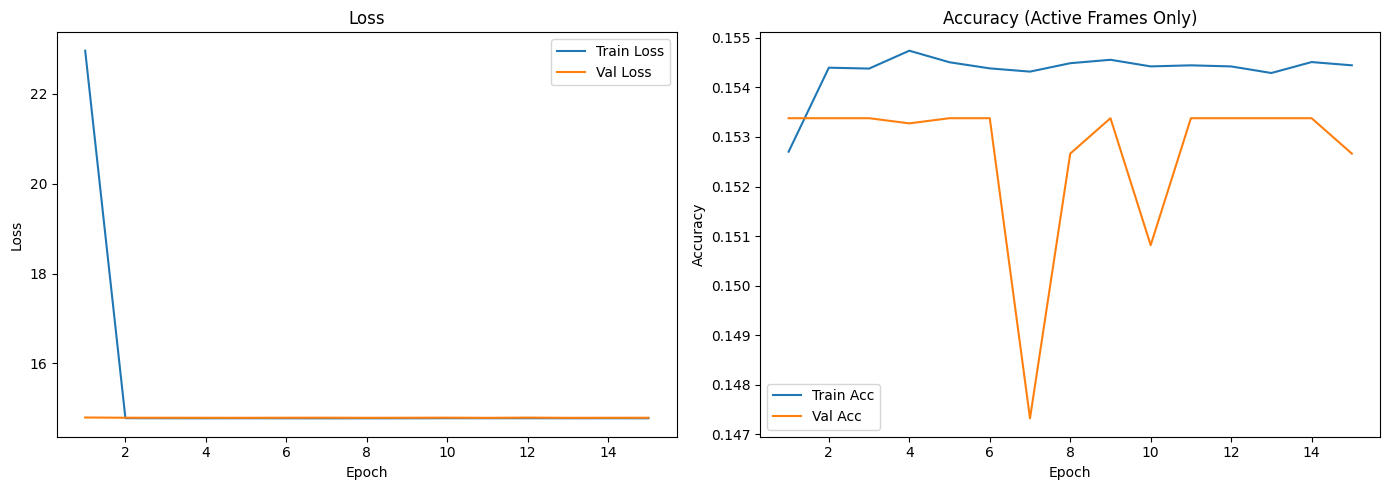

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random

def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

base_model = baseline_ANN().to(device)
N_EPOCHS = 15
N_STRINGS = 6
# Loss with low weight for muted class
weights = torch.ones(21)
weights[20] = 0.01
criterion = nn.CrossEntropyLoss(weight=weights.to(device))

# Re-initialize model
set_seed(42)
base_model = baseline_ANN().to(device)
optimizer = optim.Adam(base_model.parameters(), lr=0.01)

def train_one_epoch_all(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(x)

        loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total += x.size(0)

        for s in range(N_STRINGS):
            preds = outputs[s].argmax(dim=1).cpu()
            y_cpu = y[:, s].cpu()
            correct[s] += (preds == y_cpu).sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / total for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc


def evaluate_all(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
            total_loss += loss.item()
            total += x.size(0)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu()
                y_cpu = y[:, s].cpu()
                correct[s] += (preds == y_cpu).sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / total for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    active_total = [0.0] * N_STRINGS
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(x)

        loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total += x.size(0)

        for s in range(N_STRINGS):
            preds = outputs[s].argmax(dim=1).cpu()
            y_cpu = y[:, s].cpu()
            active_mask = y_cpu != 20
            if active_mask.sum() > 0:
                correct[s] += (preds[active_mask] == y_cpu[active_mask]).sum().item()
                active_total[s] += active_mask.sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / active_total[s] if active_total[s] > 0 else 0.0 for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    active_total = [0.0] * N_STRINGS
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
            total_loss += loss.item()
            total += x.size(0)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu()
                y_cpu = y[:, s].cpu()
                active_mask = y_cpu != 20
                if active_mask.sum() > 0:
                    correct[s] += (preds[active_mask] == y_cpu[active_mask]).sum().item()
                    active_total[s] += active_mask.sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / active_total[s] if active_total[s] > 0 else 0.0 for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc


# Training loop
string_names = ['E', 'A', 'D', 'G', 'B', 'e']
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(N_EPOCHS):
    train_loss, train_acc, train_per_string = train_one_epoch(base_model, train_loader, optimizer, criterion)
    val_loss, val_acc, val_per_string       = evaluate(base_model, val_loader, criterion)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}/{N_EPOCHS} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    
    per_string_str = " | ".join([f"{string_names[s]}: {val_per_string[s]:.4f}" for s in range(N_STRINGS)])
    print(f"  Val per string → {per_string_str}")

# Save after last epoch
torch.save(base_model.state_dict(), "ann_model.pth")
print("\nModel saved.")

# Plot
epochs = range(1, N_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history['train_loss'], label='Train Loss')
axes[0].plot(epochs, history['val_loss'],   label='Val Loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs, history['train_acc'], label='Train Acc')
axes[1].plot(epochs, history['val_acc'],   label='Val Acc')
axes[1].set_title('Accuracy (Active Frames Only)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()



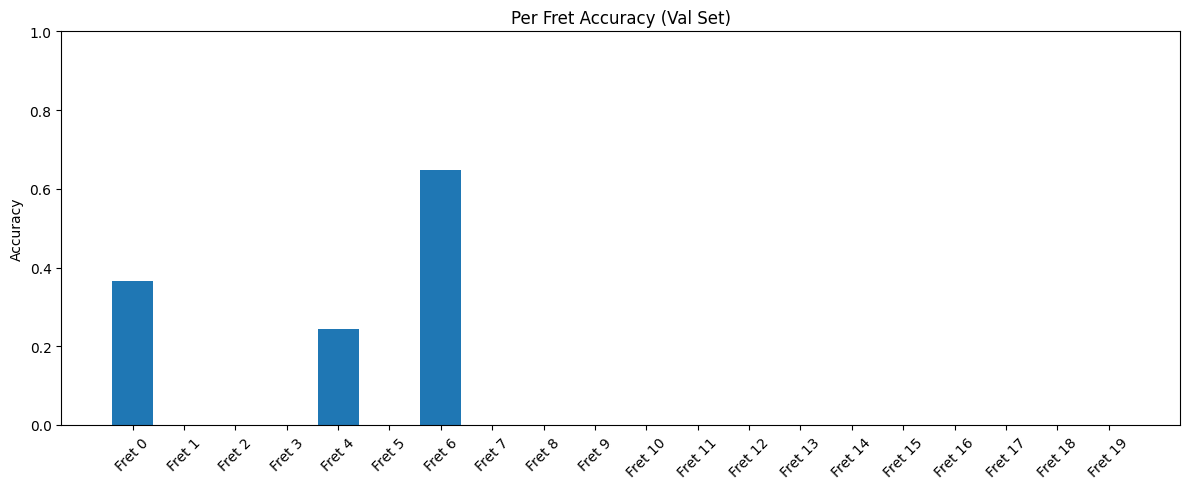

Fret  0: 0.3658 (36.6%)
Fret  1: 0.0000 (0.0%)
Fret  2: 0.0000 (0.0%)
Fret  3: 0.0000 (0.0%)
Fret  4: 0.2444 (24.4%)
Fret  5: 0.0000 (0.0%)
Fret  6: 0.6469 (64.7%)
Fret  7: 0.0000 (0.0%)
Fret  8: 0.0000 (0.0%)
Fret  9: 0.0000 (0.0%)
Fret 10: 0.0000 (0.0%)
Fret 11: 0.0000 (0.0%)
Fret 12: 0.0000 (0.0%)
Fret 13: 0.0000 (0.0%)
Fret 14: 0.0000 (0.0%)
Fret 15: 0.0000 (0.0%)
Fret 16: 0.0000 (0.0%)
Fret 17: 0.0000 (0.0%)
Fret 18: 0.0000 (0.0%)
Fret 19: 0.0000 (0.0%)


In [18]:
def evaluate_per_fret(model, loader):
    model.eval()
    # correct and total per fret (0-19), ignore muted (20)
    correct = np.zeros(20)
    total   = np.zeros(20)

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu().numpy()
                y_cpu = y[:, s].cpu().numpy()

                for fret in range(20):
                    mask = y_cpu == fret
                    if mask.sum() > 0:
                        correct[fret] += (preds[mask] == fret).sum()
                        total[fret]   += mask.sum()

    per_fret_acc = np.where(total > 0, correct / total, 0.0)
    return per_fret_acc


# Run after training
per_fret_acc = evaluate_per_fret(base_model, val_loader)

# Plot
plt.figure(figsize=(12, 5))
plt.bar(range(20), per_fret_acc)
plt.xticks(range(20), [f"Fret {i}" for i in range(20)], rotation=45)
plt.ylabel("Accuracy")
plt.title("Per Fret Accuracy (Val Set)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Print
for i, acc in enumerate(per_fret_acc):
    print(f"Fret {i:2d}: {acc:.4f} ({100*acc:.1f}%)")

In [42]:
print(f"Total frames: {len(full_dataset)}")
print(f"Train frames: {len(train_dataset)}")
print(f"Val frames:   {len(val_dataset)}")
print(f"Test frames:  {len(test_dataset)}")

# Also check how many are active vs muted in total
is_active = (all_labels != 20).any(axis=1)
print(f"\nActive frames: {is_active.sum()} ({100*is_active.sum()/len(all_labels):.1f}%)")
print(f"Muted frames:  {(~is_active).sum()} ({100*(~is_active).sum()/len(all_labels):.1f}%)")

Total frames: 472560
Train frames: 378048
Val frames:   47256
Test frames:  47256

Active frames: 374938 (79.3%)
Muted frames:  97622 (20.7%)


In [43]:
# Check a single batch to see what the model outputs look like
base_model.eval()
x, y = next(iter(val_loader))
x, y = x.to(device), y.to(device)

with torch.no_grad():
    outputs = base_model(x)

# Look at raw output probabilities for string 0
probs = torch.softmax(outputs[0], dim=1)
print("Mean probability per class (string 0):")
print(probs.mean(dim=0).cpu().numpy().round(3))

print(f"\nMost predicted class: {outputs[0].argmax(dim=1).mode().values.item()}")
print(f"True label sample: {y[:10, 0].cpu().numpy()}")

Mean probability per class (string 0):
[0.113 0.087 0.068 0.096 0.099 0.046 0.082 0.026 0.02  0.012 0.008 0.001
 0.001 0.    0.    0.    0.    0.    0.    0.    0.341]

Most predicted class: 20
True label sample: [20 20 20 20  2 20 20 20 20 20]



Model saved.


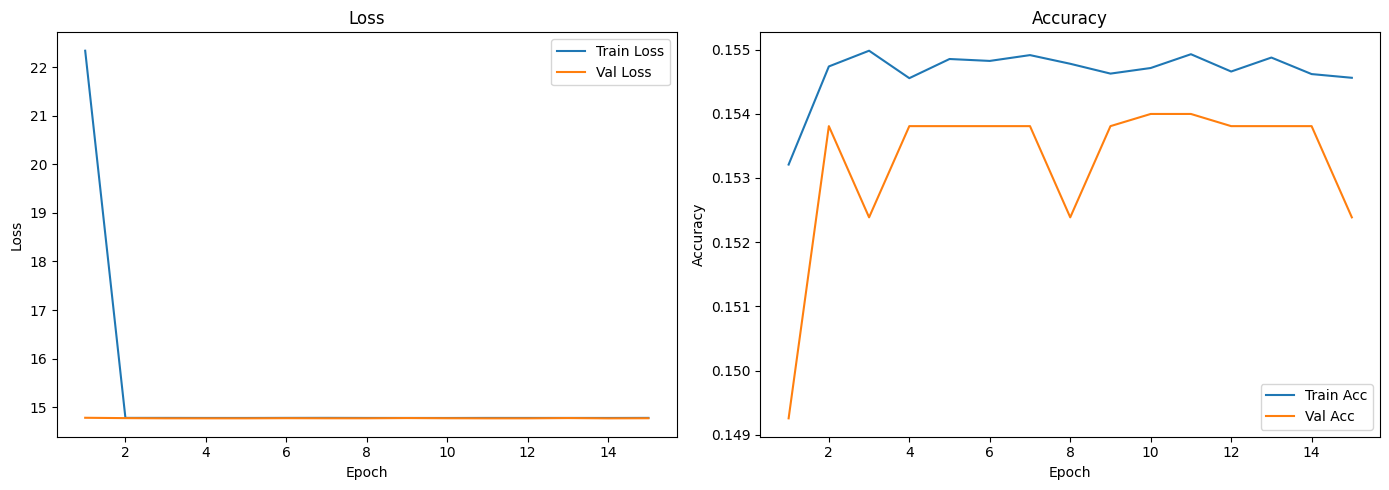

In [19]:
# Save after last epoch
torch.save(base_model.state_dict(), "ann_model.pth")
print("\nModel saved.")

# Plot
epochs = range(1, N_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history['train_loss'], label='Train Loss')
axes[0].plot(epochs, history['val_loss'],   label='Val Loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs, history['train_acc'], label='Train Acc')
axes[1].plot(epochs, history['val_acc'],   label='Val Acc')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

## Section 2.2: Actual model


In [15]:
class GuitarCNN(nn.Module):
    def __init__(self, 
                 conv_channels=[32, 64], 
                 fc_units=256, 
                 dropout_rate=0.3,
                 act_fn=nn.ReLU): # Pass the class, not the instance
        super(GuitarCNN, self).__init__()
        
        self.conv_block = nn.Sequential(
            nn.Conv2d(1, conv_channels[0], kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(conv_channels[0]),
            act_fn(), # Instantiate the chosen function
            nn.MaxPool2d(kernel_size=(2, 1)), 
            
            nn.Conv2d(conv_channels[0], conv_channels[1], kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(conv_channels[1]),
            act_fn(), 
            nn.MaxPool2d(kernel_size=(2, 1)), 
            
            nn.Dropout(dropout_rate)
        )
        
        self.flatten_size = conv_channels[1] * 48 * 9
        
        self.fc_shared = nn.Sequential(
            nn.Linear(self.flatten_size, fc_units),
            act_fn(),
            nn.Dropout(dropout_rate)
        )
        
        self.output_heads = nn.ModuleList([
            nn.Linear(fc_units, 21) for _ in range(6)#21 classes, 6 strings
        ])
    
    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1) 
        x = self.conv_block(x)
        x = x.view(x.size(0), -1) 
        x = self.fc_shared(x)
        return [head(x) for head in self.output_heads]



In [14]:
def train_one_epoch_all(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(x)

        loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
        total += x.size(0)

        for s in range(N_STRINGS):
            preds = outputs[s].argmax(dim=1).cpu()
            y_cpu = y[:, s].cpu()
            correct[s] += (preds == y_cpu).sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / total for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc


def evaluate_all(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
            total_loss += loss.item()
            total += x.size(0)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu()
                y_cpu = y[:, s].cpu()
                correct[s] += (preds == y_cpu).sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / total for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc

def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = [0.0] * N_STRINGS
    active_total = [0.0] * N_STRINGS
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            loss = sum(criterion(outputs[s], y[:, s]) for s in range(N_STRINGS))
            total_loss += loss.item()
            total += x.size(0)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu()
                y_cpu = y[:, s].cpu()
                active_mask = y_cpu != 20
                if active_mask.sum() > 0:
                    correct[s] += (preds[active_mask] == y_cpu[active_mask]).sum().item()
                    active_total[s] += active_mask.sum().item()

    avg_loss = total_loss / len(loader)
    per_string_acc = [correct[s] / active_total[s] if active_total[s] > 0 else 0.0 for s in range(N_STRINGS)]
    avg_acc = sum(per_string_acc) / N_STRINGS
    return avg_loss, avg_acc, per_string_acc


Epoch 10/110 | Loss: 0.0730 | Acc: 0.9115
Epoch 20/110 | Loss: 0.0200 | Acc: 0.9753
Epoch 30/110 | Loss: 0.0164 | Acc: 0.9674
Epoch 40/110 | Loss: 0.0083 | Acc: 0.9818
Epoch 50/110 | Loss: 0.0054 | Acc: 0.9909
Epoch 60/110 | Loss: 0.0021 | Acc: 0.9922
Epoch 70/110 | Loss: 0.0045 | Acc: 0.9954
Epoch 80/110 | Loss: 0.0025 | Acc: 0.9948
Epoch 90/110 | Loss: 0.0012 | Acc: 0.9941
Epoch 100/110 | Loss: 0.0019 | Acc: 0.9967
Epoch 110/110 | Loss: 0.0006 | Acc: 0.9987


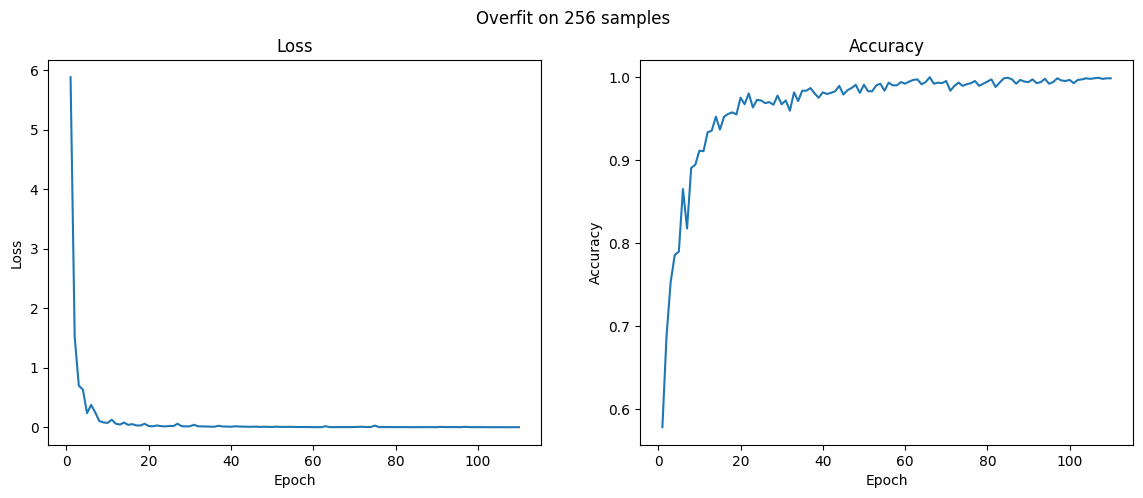

In [ ]:
#overfit
# Take a small subset to overfit on
small_windows = all_windows[:256]
small_labels  = all_labels[:256]

small_dataset = GuitarSetDataset(small_windows, small_labels)
small_loader  = DataLoader(small_dataset, batch_size=32, shuffle=True)

# Initialize model
set_seed(42)
cnn_model = GuitarCNN(
    conv_channels=[32, 64], 
    fc_units=256, 
    dropout_rate=0.3, 
    act_fn=nn.ReLU
).to(device)
optimizer = optim.Adam(cnn_model.parameters(), lr=0.0005)

weights = torch.ones(21)
weights[20] = 0.01
criterion = nn.CrossEntropyLoss(weight=weights.to(device))

N_EPOCHS = 110
history = {'loss': [], 'acc': []}

for epoch in range(N_EPOCHS):
    loss, acc, _ = train_one_epoch_all(cnn_model, small_loader, optimizer, criterion)
    history['loss'].append(loss)
    history['acc'].append(acc)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{N_EPOCHS} | Loss: {loss:.4f} | Acc: {acc:.4f}")

# Plot
epochs = range(1, N_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history['loss'])
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')

axes[1].plot(epochs, history['acc'])
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')

plt.suptitle('Overfit on 256 samples')

plt.show()


Config 1/8: {'conv_channels': [32, 64], 'fc_units': 128, 'dropout_rate': 0.4, 'lr': 0.00030887567507992714, 'act_fn': <class 'torch.nn.modules.activation.ReLU'>, 'muted_weight': 0.076}
  Epoch 10/30 | Train Loss: 2.5199, Train Acc: 0.8874 | Val Loss: 1.2665, Val Acc: 0.9575
  Epoch 20/30 | Train Loss: 2.1265, Train Acc: 0.9053 | Val Loss: 1.0655, Val Acc: 0.9656
  Epoch 30/30 | Train Loss: 1.9731, Train Acc: 0.9121 | Val Loss: 0.9939, Val Acc: 0.9669
  Best Val Acc: 0.9703

Config 2/8: {'conv_channels': [32, 64], 'fc_units': 512, 'dropout_rate': 0.27, 'lr': 0.00011470819313402349, 'act_fn': <class 'torch.nn.modules.activation.ReLU'>, 'muted_weight': 0.031}
  Epoch 10/30 | Train Loss: 0.3682, Train Acc: 0.9904 | Val Loss: 0.4056, Val Acc: 0.9872
  Epoch 20/30 | Train Loss: 0.2336, Train Acc: 0.9950 | Val Loss: 0.3394, Val Acc: 0.9890
  Epoch 30/30 | Train Loss: 0.1799, Train Acc: 0.9965 | Val Loss: 0.3378, Val Acc: 0.9878
  Best Val Acc: 0.9891

Config 3/8: {'conv_channels': [32, 64], 

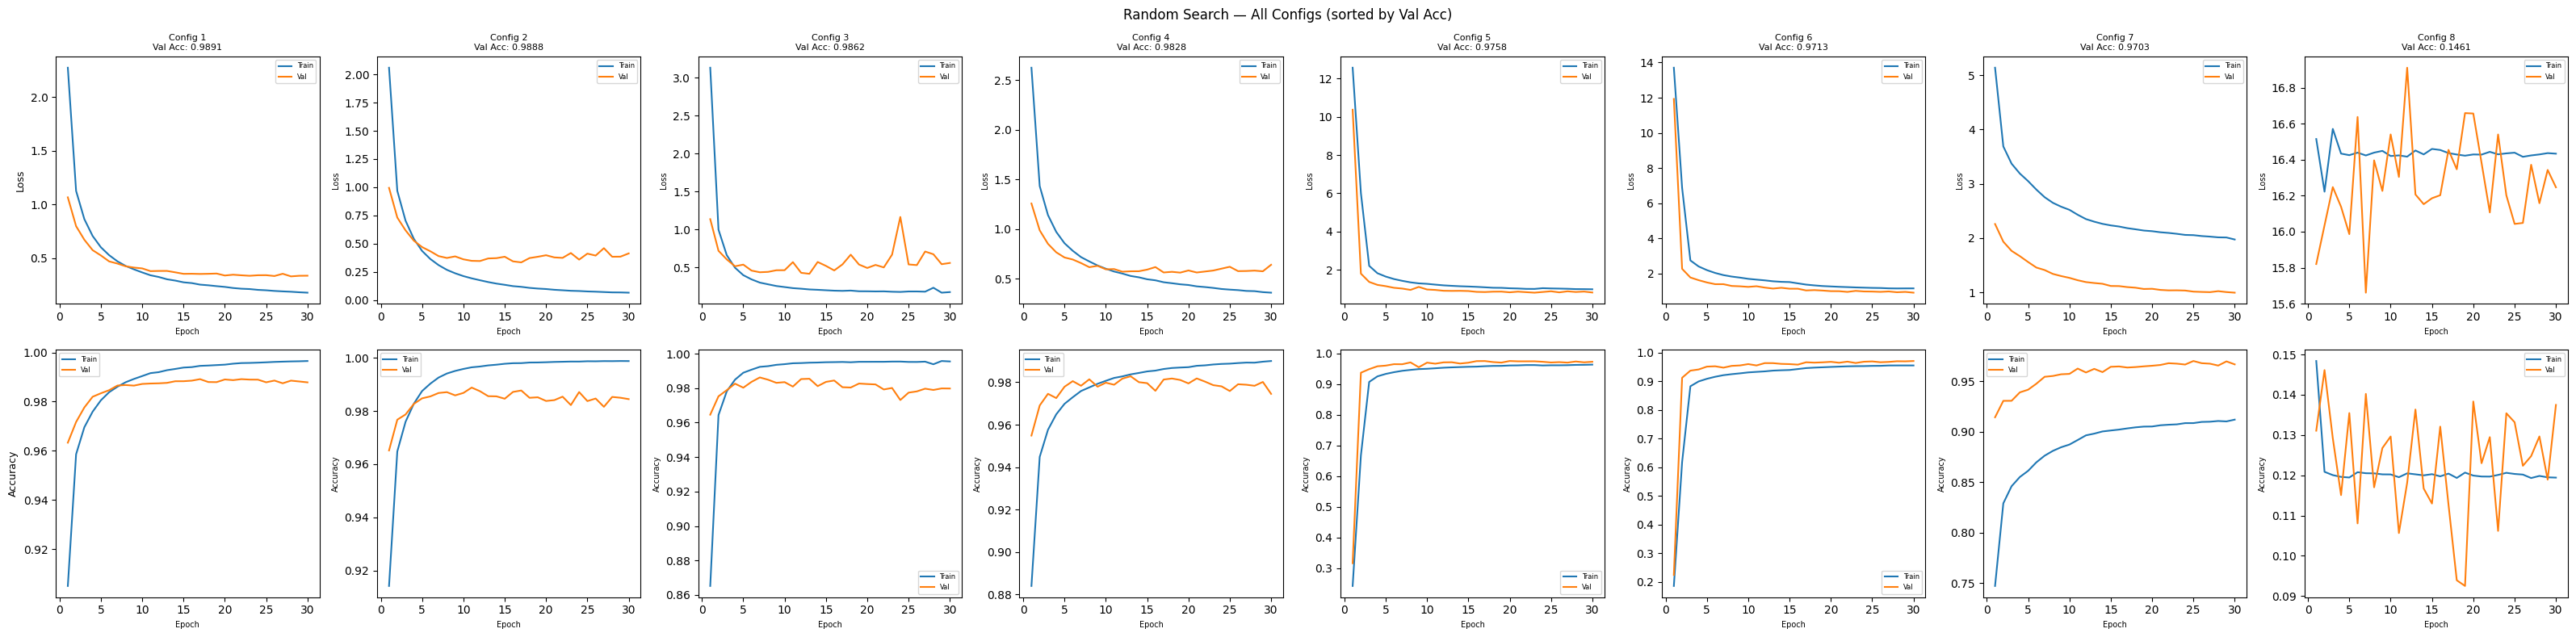

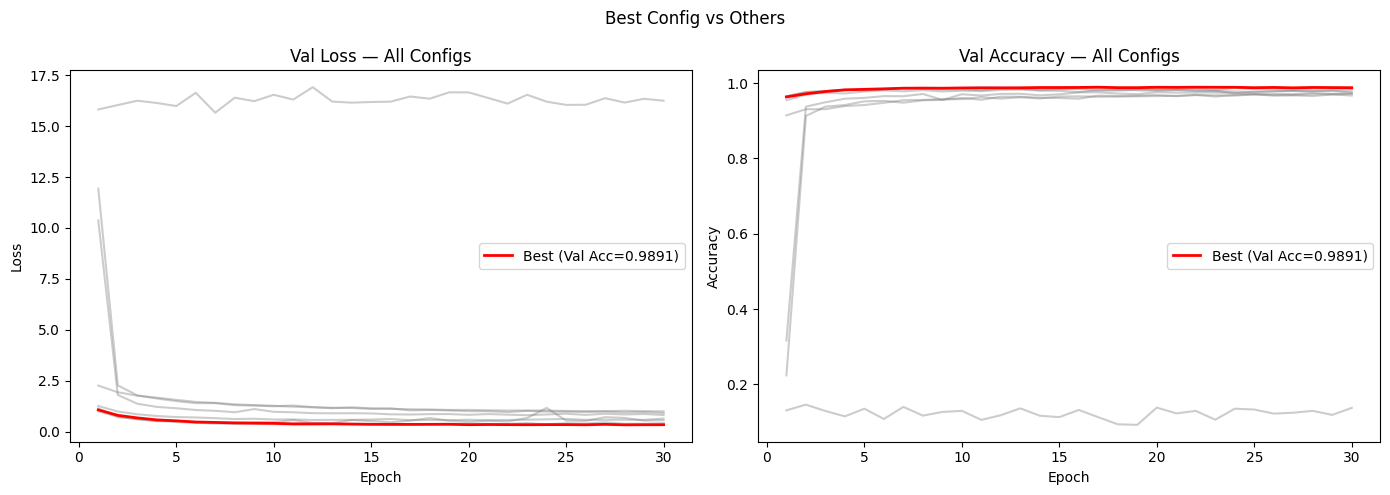


Best Config: {'conv_channels': [32, 64], 'fc_units': 512, 'dropout_rate': 0.27, 'lr': 0.00011470819313402349, 'act_fn': <class 'torch.nn.modules.activation.ReLU'>, 'muted_weight': 0.031}
Best Val Acc: 0.9891


In [ ]:
import random
import numpy as np

def sample_config():
    return {
        'conv_channels': random.choice([[32, 64], [64, 128], [32, 128], [64, 64]]),  # discrete, no range makes sense here
        'fc_units': random.choice([128, 256, 512]),                                   # discrete
        'dropout_rate': round(random.uniform(0.1, 0.5), 2),                          # continuous range
        'lr': 10 ** random.uniform(-4, -2),                                           # log scale: 0.0001 to 0.01
        'act_fn': random.choice([nn.ReLU, nn.ELU, nn.LeakyReLU]),                    # discrete
        'muted_weight': round(random.uniform(0.01, 0.1), 3),                         # continuous range
    }

N_SEARCH = 8
N_EPOCHS = 30

results = []
all_histories = []
random.seed(42)
np.random.seed(42)
for i in range(N_SEARCH):
    config = sample_config()
    print(f"\nConfig {i+1}/{N_SEARCH}: {config}")

    
    model = GuitarCNN(
        conv_channels=config['conv_channels'],
        fc_units=config['fc_units'],
        dropout_rate=config['dropout_rate'],
        act_fn=config['act_fn']
    ).to(device)

    weights = torch.ones(21)
    weights[20] = config['muted_weight']
    criterion = nn.CrossEntropyLoss(weight=weights.to(device))
    optimizer = optim.Adam(model.parameters(), lr=config['lr'])

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0

    for epoch in range(N_EPOCHS):
        train_loss, train_acc, _ = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, _     = evaluate(model, val_loader, criterion)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc

        if (epoch + 1) % 10 == 0:
            print(f"  Epoch {epoch+1}/{N_EPOCHS} | "
            f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    results.append((best_val_acc, config, history))
    all_histories.append((config, history))
    print(f"  Best Val Acc: {best_val_acc:.4f}")


# Sort by best val acc
results.sort(key=lambda x: -x[0])

# --- Summary Table ---
print("\n--- All Configs Summary ---")
print(f"{'Rank':<6} {'Val Acc':<10} {'lr':<8} {'fc_units':<10} {'dropout':<10} {'channels':<15} {'act_fn':<12} {'muted_w':<10}")
for rank, (acc, cfg, _) in enumerate(results):
    print(f"{rank+1:<6} {acc:<10.4f} {cfg['lr']:<8} {cfg['fc_units']:<10} {cfg['dropout_rate']:<10} "
          f"{str(cfg['conv_channels']):<15} {cfg['act_fn'].__name__:<12} {cfg['muted_weight']:<10}")

# --- Plot all configs: Loss ---
fig, axes = plt.subplots(2, N_SEARCH, figsize=(N_SEARCH * 4, 8))
epochs = range(1, N_EPOCHS + 1)

for i, (acc, cfg, history) in enumerate(results):
    label = f"C{i+1} | lr={cfg['lr']} | fc={cfg['fc_units']}\ndrop={cfg['dropout_rate']} | {cfg['act_fn'].__name__}"

    axes[0, i].plot(epochs, history['train_loss'], label='Train')
    axes[0, i].plot(epochs, history['val_loss'],   label='Val')
    axes[0, i].set_title(f"Config {i+1}\nVal Acc: {acc:.4f}", fontsize=8)
    axes[0, i].set_xlabel('Epoch', fontsize=7)
    axes[0, i].set_ylabel('Loss', fontsize=7)
    axes[0, i].legend(fontsize=6)

    axes[1, i].plot(epochs, history['train_acc'], label='Train')
    axes[1, i].plot(epochs, history['val_acc'],   label='Val')
    axes[1, i].set_xlabel('Epoch', fontsize=7)
    axes[1, i].set_ylabel('Accuracy', fontsize=7)
    axes[1, i].legend(fontsize=6)

axes[0, 0].set_ylabel('Loss', fontsize=9)
axes[1, 0].set_ylabel('Accuracy', fontsize=9)
fig.suptitle('Random Search — All Configs (sorted by Val Acc)', fontsize=12)
plt.tight_layout()
plt.show()

# --- Plot best config highlighted vs others ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for acc, cfg, history in results[1:]:  # all except best
    axes[0].plot(epochs, history['val_loss'], color='gray', alpha=0.4)
    axes[1].plot(epochs, history['val_acc'],  color='gray', alpha=0.4)

# Best config on top
best_acc, best_cfg, best_history = results[0]
axes[0].plot(epochs, best_history['val_loss'], color='red',  linewidth=2, label=f'Best (Val Acc={best_acc:.4f})')
axes[1].plot(epochs, best_history['val_acc'],  color='red',  linewidth=2, label=f'Best (Val Acc={best_acc:.4f})')

axes[0].set_title('Val Loss — All Configs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].set_title('Val Accuracy — All Configs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.suptitle('Best Config vs Others', fontsize=12)
plt.tight_layout()
plt.show()

# Print best config
print(f"\nBest Config: {best_cfg}")
print(f"Best Val Acc: {best_acc:.4f}")

In [22]:
# Run best config again and save weights(cus I forgot to do it before :()
model = GuitarCNN(
    conv_channels=[32, 64],
    fc_units=512,
    dropout_rate=0.27,
    act_fn=nn.ReLU
).to(device)

weights = torch.ones(21)    
weights[20] = 0.031
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
optimizer = optim.Adam(model.parameters(), lr=0.000115)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(30):
    train_loss, train_acc, _ = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc, _     = evaluate(model, val_loader, criterion)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f"  Epoch {epoch+1}/{N_EPOCHS} | "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

# Save final weights
torch.save(model.state_dict(), "best_cnn_model.pth")
print(f"Model saved. Final val acc: {val_acc:.4f}")

  Epoch 10/15 | Train Loss: 0.3655, Train Acc: 0.9905 | Val Loss: 0.4026, Val Acc: 0.9875
  Epoch 20/15 | Train Loss: 0.2310, Train Acc: 0.9953 | Val Loss: 0.3717, Val Acc: 0.9870
  Epoch 30/15 | Train Loss: 0.1799, Train Acc: 0.9965 | Val Loss: 0.3683, Val Acc: 0.9869
Model saved. Final val acc: 0.9869


In [18]:
#load the weights   
model = GuitarCNN(
    conv_channels=[32, 64],
    fc_units=512,
    dropout_rate=0.27,
    act_fn=nn.ReLU
).to(device)

model.load_state_dict(torch.load("best_cnn_model.pth", map_location=device))

C:\Users\sahan\AppData\Local\Temp\ipykernel_15792\2601379670.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_cnn_model.pth", map_l

<All keys matched successfully>

In [24]:
#test set evaluation
test_loss, test_acc, per_string_acc = evaluate(model, test_loader, criterion)

print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f}")
for i, acc in enumerate(per_string_acc):
    print(f"  String {i+1}: {acc:.4f}")

Test Loss: 0.3635 | Test Acc: 0.9871
  String 1: 0.9889
  String 2: 0.9895
  String 3: 0.9879
  String 4: 0.9874
  String 5: 0.9861
  String 6: 0.9830


Fret  0: 0.9872 (98.7%)
Fret  1: 0.9806 (98.1%)
Fret  2: 0.9909 (99.1%)
Fret  3: 0.9908 (99.1%)
Fret  4: 0.9876 (98.8%)
Fret  5: 0.9868 (98.7%)
Fret  6: 0.9906 (99.1%)
Fret  7: 0.9842 (98.4%)
Fret  8: 0.9893 (98.9%)
Fret  9: 0.9803 (98.0%)
Fret 10: 0.9845 (98.5%)
Fret 11: 0.9793 (97.9%)
Fret 12: 0.9730 (97.3%)
Fret 13: 0.9911 (99.1%)
Fret 14: 0.9633 (96.3%)
Fret 15: 0.9900 (99.0%)
Fret 16: 1.0000 (100.0%)
Fret 17: 1.0000 (100.0%)
Fret 18: 1.0000 (100.0%)
Fret 19: 1.0000 (100.0%)
Muted  : 0.9324 (93.2%)


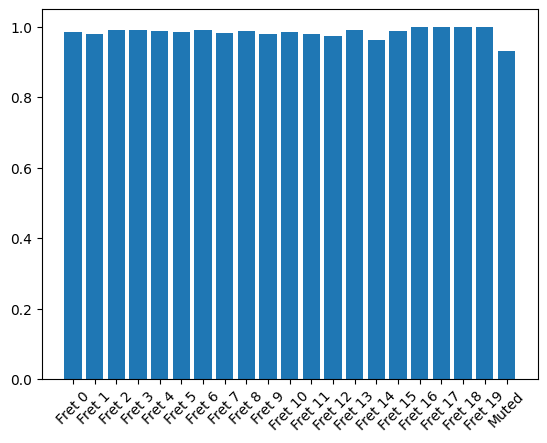

In [28]:
def evaluate_per_fret(model, loader):
    model.eval()
    correct = np.zeros(21)  # 0-19 frets + 20 muted
    total   = np.zeros(21)

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu().numpy()
                y_cpu = y[:, s].cpu().numpy()

                for fret in range(21):  # now includes muted
                    mask = y_cpu == fret
                    if mask.sum() > 0:
                        correct[fret] += (preds[mask] == fret).sum()
                        total[fret]   += mask.sum()

    per_fret_acc = np.where(total > 0, correct / total, 0.0)
    return per_fret_acc

per_fret_acc = evaluate_per_fret(model, test_loader)

labels = [f"Fret {i}" for i in range(20)] + ["Muted"]
plt.bar(range(21), per_fret_acc)
plt.xticks(range(21), labels, rotation=45)

for i, acc in enumerate(per_fret_acc):
    label = f"Fret {i:2d}" if i < 20 else "Muted  "
    print(f"{label}: {acc:.4f} ({100*acc:.1f}%)")

In [29]:
!pip install seaborn

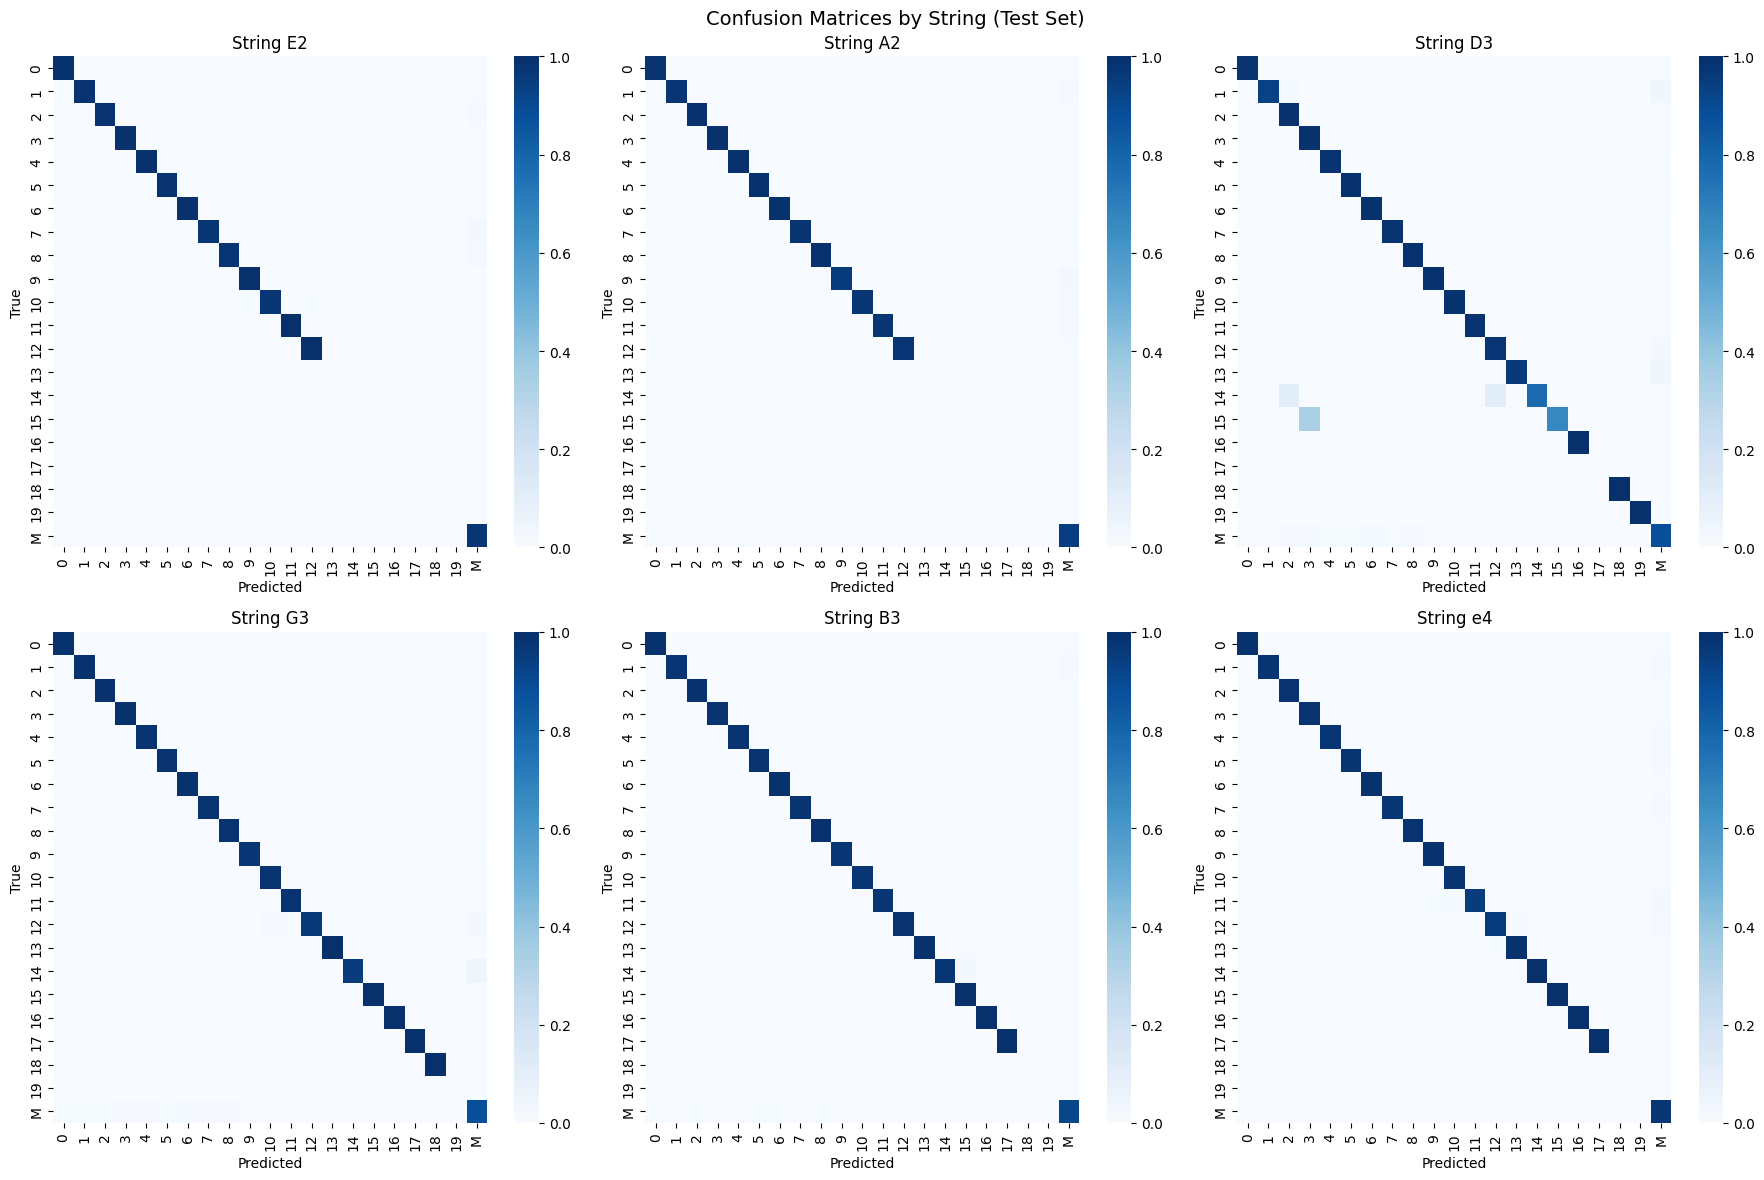

In [30]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrices(model, loader):
    model.eval()
    all_preds = [[] for _ in range(N_STRINGS)]
    all_true  = [[] for _ in range(N_STRINGS)]

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)

            for s in range(N_STRINGS):
                preds = outputs[s].argmax(dim=1).cpu().numpy()
                true  = y[:, s].cpu().numpy()
                all_preds[s].extend(preds)
                all_true[s].extend(true)

    string_names = ['E2', 'A2', 'D3', 'G3', 'B3', 'e4']
    class_labels = [str(i) for i in range(20)] + ['M']  # M = muted

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    for s in range(N_STRINGS):
        cm = confusion_matrix(all_true[s], all_preds[s], labels=list(range(21)))
        # Normalize by row (true label)
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

        sns.heatmap(cm_norm, ax=axes[s], cmap='Blues', vmin=0, vmax=1,
                    xticklabels=class_labels, yticklabels=class_labels,
                    cbar=True)
        axes[s].set_title(f'String {string_names[s]}')
        axes[s].set_xlabel('Predicted')
        axes[s].set_ylabel('True')

    plt.suptitle('Confusion Matrices by String (Test Set)', fontsize=14)
    plt.tight_layout()
    plt.show()

plot_confusion_matrices(model, test_loader)

In [32]:
model.eval()
wrong_examples = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = model(x)

        preds = torch.stack([outputs[s].argmax(dim=1) for s in range(N_STRINGS)], dim=1)  # (batch, 6)
        
        for i in range(x.size(0)):
            if not (preds[i] == y[i]).all():  # at least one string wrong
                wrong_examples.append((x[i].cpu(), y[i].cpu(), preds[i].cpu()))
            
            if len(wrong_examples) >= 5:  # collect 5 examples
                break
        
        if len(wrong_examples) >= 5:
            break

# Display them
string_names = ['E2', 'A2', 'D3', 'G3', 'B3', 'e4']

for ex_idx, (xi, yi, pi) in enumerate(wrong_examples):
    print(f"\n--- Example {ex_idx+1} ---")
    print(f"{'String':<6} {'True':>6} {'Pred':>6} {'Correct':>8}")
    print("-" * 30)
    for s in range(N_STRINGS):
        true_label = "M" if yi[s].item() == 20 else str(yi[s].item())
        pred_label = "M" if pi[s].item() == 20 else str(pi[s].item())
        correct = "✓" if yi[s].item() == pi[s].item() else "✗"
        print(f"{string_names[s]:<6} {true_label:>6} {pred_label:>6} {correct:>8}")


--- Example 1 ---
String   True   Pred  Correct
------------------------------
E2          3      3        ✓
A2          5      5        ✓
D3          3      3        ✓
G3          M      3        ✗
B3          3      3        ✓
e4          3      3        ✓

--- Example 2 ---
String   True   Pred  Correct
------------------------------
E2          M      M        ✓
A2          M      M        ✓
D3          M     10        ✗
G3          7      7        ✓
B3          M      M        ✓
e4          M      M        ✓

--- Example 3 ---
String   True   Pred  Correct
------------------------------
E2          9      9        ✓
A2         11     11        ✓
D3         11     11        ✓
G3         10     10        ✓
B3          M      9        ✗
e4          M      9        ✗

--- Example 4 ---
String   True   Pred  Correct
------------------------------
E2          M      M        ✓
A2          M      M        ✓
D3          M     10        ✗
G3          M      M        ✓
B3          M      M

In [33]:
model.eval()
muted_as_true = 0
active_as_true = 0

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = model(x)

        preds = torch.stack([outputs[s].argmax(dim=1) for s in range(N_STRINGS)], dim=1)

        for s in range(N_STRINGS):
            wrong_mask = preds[:, s] != y[:, s]  # mispredicted
            true_labels_of_wrong = y[:, s][wrong_mask]

            muted_as_true  += (true_labels_of_wrong == 20).sum().item()
            active_as_true += (true_labels_of_wrong != 20).sum().item()

total_wrong = muted_as_true + active_as_true
print(f"Total mispredictions:          {total_wrong}")
print(f"True label was muted:          {muted_as_true} ({100*muted_as_true/total_wrong:.1f}%)")
print(f"True label was active fret:    {active_as_true} ({100*active_as_true/total_wrong:.1f}%)")

Total mispredictions:          14696
True label was muted:          13661 (93.0%)
True label was active fret:    1035 (7.0%)


C:\Users\sahan\AppData\Local\Temp\ipykernel_21076\1728464316.py:42: RuntimeWarning: invalid value encountered in divide
  pct_per_combo  = np.where(total_per_combo  > 0, 100 * wrong_per_combo  / total_per_combo,  0)


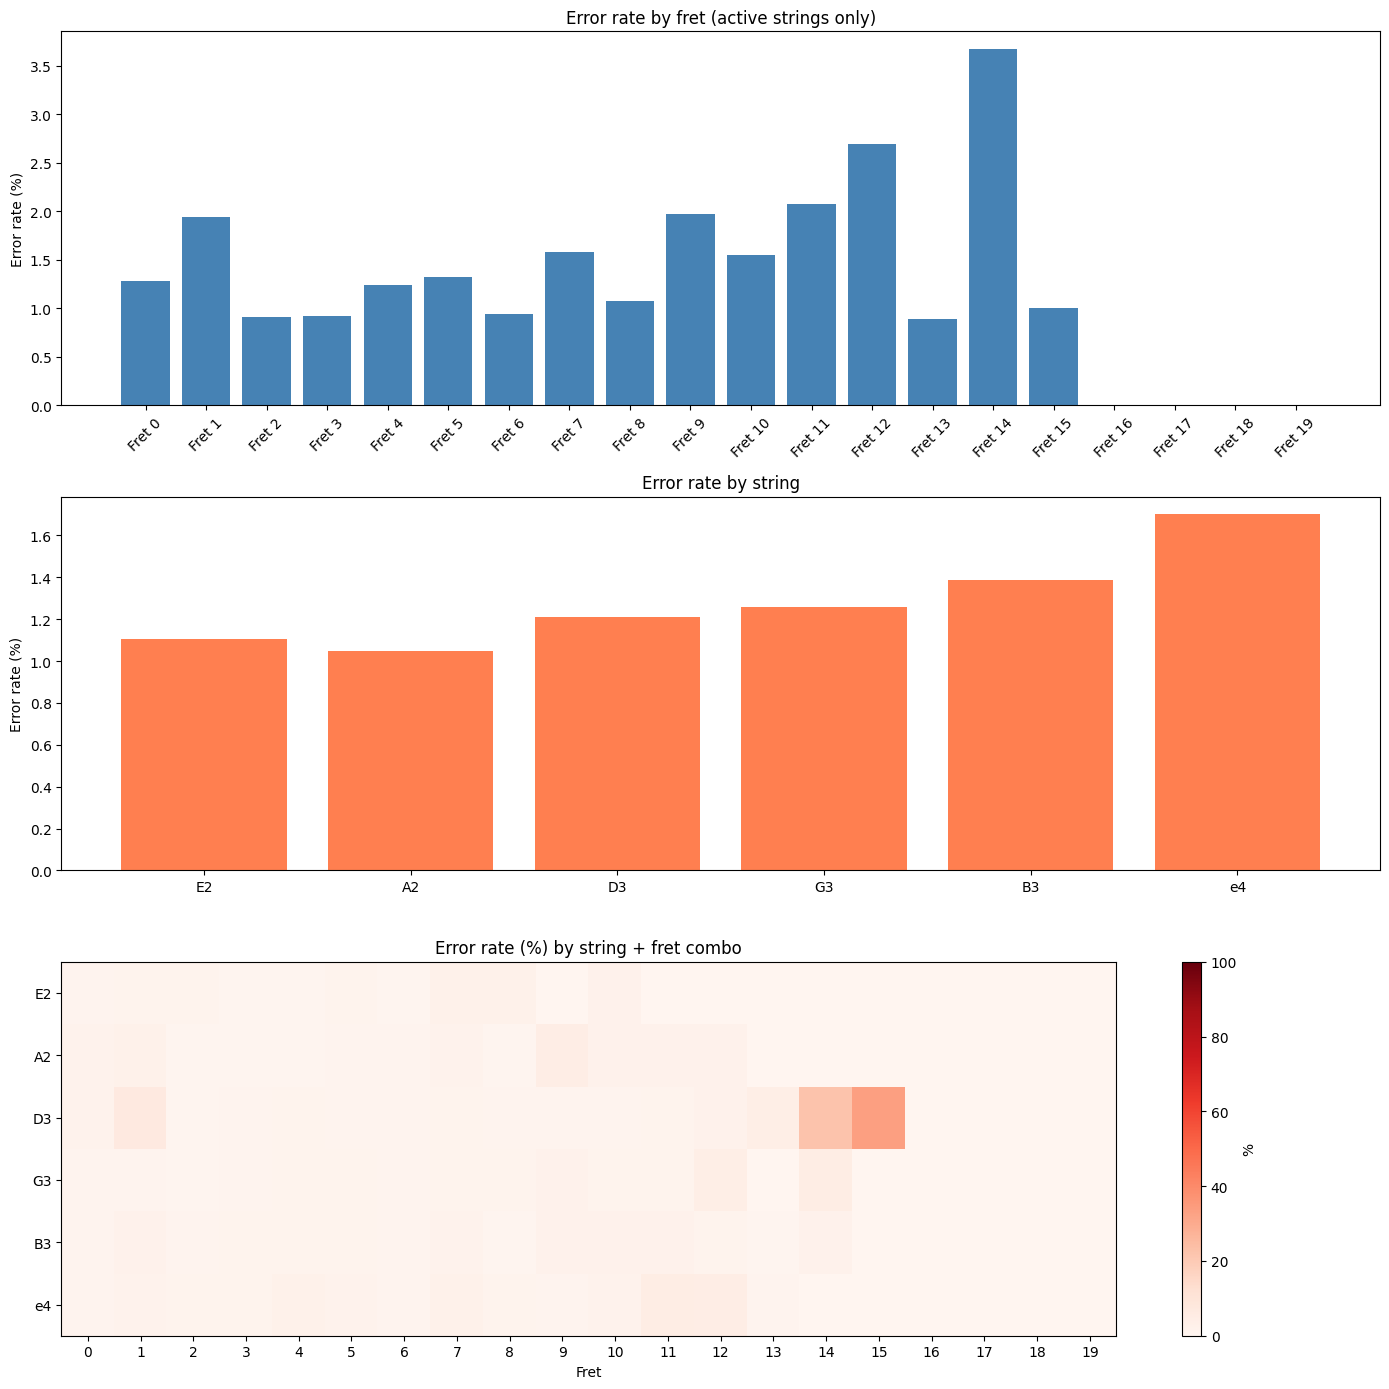

In [36]:
import numpy as np
import matplotlib.pyplot as plt

model.eval()
string_names = ['E2', 'A2', 'D3', 'G3', 'B3', 'e4']

wrong_per_fret   = np.zeros(20)
wrong_per_string = np.zeros(N_STRINGS)
wrong_per_combo  = np.zeros((N_STRINGS, 20))  # string x fret

# total active frames per fret / string for percentage
total_per_fret   = np.zeros(20)
total_per_string = np.zeros(N_STRINGS)
total_per_combo  = np.zeros((N_STRINGS, 20))

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = model(x)
        preds = torch.stack([outputs[s].argmax(dim=1) for s in range(N_STRINGS)], dim=1)

        for s in range(N_STRINGS):
            active_mask = y[:, s] != 20
            true_labels = y[:, s][active_mask].cpu().numpy()
            wrong_mask  = (preds[:, s] != y[:, s]) & (y[:, s] != 20)
            wrong_labels = y[:, s][wrong_mask].cpu().numpy()

            total_per_string[s] += active_mask.sum().item()
            wrong_per_string[s] += wrong_mask.sum().item()

            for fret in true_labels:
                total_per_fret[fret] += 1
                total_per_combo[s, fret] += 1
            for fret in wrong_labels:
                wrong_per_fret[fret] += 1
                wrong_per_combo[s, fret] += 1

# convert to error rate %
pct_per_fret   = np.where(total_per_fret   > 0, 100 * wrong_per_fret   / total_per_fret,   0)
pct_per_string = np.where(total_per_string > 0, 100 * wrong_per_string / total_per_string, 0)
pct_per_combo  = np.where(total_per_combo  > 0, 100 * wrong_per_combo  / total_per_combo,  0)

fig, axes = plt.subplots(3, 1, figsize=(14, 14))

axes[0].bar(range(20), pct_per_fret, color='steelblue')
axes[0].set_xticks(range(20))
axes[0].set_xticklabels([f"Fret {i}" for i in range(20)], rotation=45)
axes[0].set_ylabel("Error rate (%)")
axes[0].set_title("Error rate by fret (active strings only)")

axes[1].bar(string_names, pct_per_string, color='coral')
axes[1].set_ylabel("Error rate (%)")
axes[1].set_title("Error rate by string")

im = axes[2].imshow(pct_per_combo, aspect='auto', cmap='Reds', vmin=0, vmax=100)
axes[2].set_xticks(range(20))
axes[2].set_xticklabels([str(i) for i in range(20)])
axes[2].set_yticks(range(N_STRINGS))
axes[2].set_yticklabels(string_names)
axes[2].set_xlabel("Fret")
axes[2].set_title("Error rate (%) by string + fret combo")
plt.colorbar(im, ax=axes[2], label="%")

plt.tight_layout()
plt.show()

In [38]:
audio_np, sr = sf.read("my_rec/Playin.wav", always_2d=True)
print(f"Sample rate: {sr}")

Sample rate: 48000


# Evaluating using my own guitar playing

In [14]:
import soundfile as sf
from scipy.signal import resample_poly
import librosa
import numpy as np

# Load
audio_np, sr = sf.read("my_rec/Playin.wav", always_2d=True)
audio_np = audio_np.mean(axis=1)  # stereo to mono

# Resample to 22050 if needed
if sr != 22050:
    audio_np = resample_poly(audio_np, up=22050, down=sr) # assumes 44100 input

# Normalize
max_val = np.abs(audio_np).max()
if max_val > 0:
    audio_np = audio_np / max_val

# CQT
cqt = librosa.cqt(audio_np, sr=22050, hop_length=512,
                  fmin=librosa.note_to_hz('C1'),
                  n_bins=192, bins_per_octave=24)
cqt_db = librosa.amplitude_to_db(np.abs(cqt), ref=np.max)

# Sliding windows — same function used in training
windows = extract_windows(cqt_db)
frame_times = np.arange(windows.shape[0]) * 512 / 22050

print(f"Recording duration: {len(audio_np)/22050:.2f}s")
print(f"Windows shape: {windows.shape}")

Recording duration: 4.39s
Windows shape: (190, 192, 9)


In [17]:
import torch
import numpy as np

model.eval()
string_names = ['E2', 'A2', 'D3', 'G3', 'B3', 'e4']

# Get predictions for all frames
all_preds = []
X = torch.tensor(windows, dtype=torch.float32).unsqueeze(1)

with torch.no_grad():
    for i in range(0, len(X), 128):  # batch it
        batch = X[i:i+128].to(device)
        outputs = model(batch)
        preds = torch.stack([outputs[s].argmax(dim=1) for s in range(6)], dim=1)
        all_preds.append(preds.cpu())

all_preds = torch.cat(all_preds, dim=0).numpy()  # (n_frames, 6)

# Print as tablature — group consecutive identical frames together
print("Generated Tablature")
print("=" * 60)
print(f"{'Time':<8} {'E2':<5} {'A2':<5} {'D3':<5} {'G3':<5} {'B3':<5} {'e4':<5}")
print("-" * 60)

prev = None
for i, (t, pred) in enumerate(zip(frame_times, all_preds)):
    # only print when something changes, skip pure muted frames
    if (pred != prev).any() and (pred != 20).any():
        row = []
        for s in range(6):
            row.append("M" if pred[s] == 20 else str(pred[s]))
        print(f"{t:<8.2f} {row[0]:<5} {row[1]:<5} {row[2]:<5} {row[3]:<5} {row[4]:<5} {row[5]:<5}")
        prev = pred.copy()

Generated Tablature
Time     E2    A2    D3    G3    B3    e4   
------------------------------------------------------------
0.53     M     M     5     M     M     M    
0.56     3     2     5     M     M     3    
0.67     3     M     5     M     M     3    
0.77     3     M     5     M     3     3    
0.81     3     M     5     7     3     3    
1.04     3     M     5     M     3     3    
1.14     3     M     5     M     3     M    
1.16     3     M     5     M     M     M    
1.21     3     M     5     M     M     3    
1.25     3     M     5     M     M     M    
1.35     3     M     5     M     M     3    
1.37     3     M     5     M     3     3    
1.39     3     M     5     0     3     3    
1.46     3     M     5     M     3     3    
1.51     3     M     5     7     3     3    
1.65     3     M     M     M     3     3    
1.67     3     M     M     M     3     M    
1.70     3     M     M     M     3     3    
1.74     3     M     5     M     3     3    
1.81     3     M   

In [20]:

N_STRINGS = 6

# Load second recording
audio_np, sr = sf.read("my_rec/bluh.wav", always_2d=True)
audio_np = audio_np.mean(axis=1)  # stereo to mono

# Resample to 22050 if needed
if sr != 22050:
    audio_np = resample_poly(audio_np, up=22050, down=sr) # assumes 44100 input

# Normalize
max_val = np.abs(audio_np).max()
if max_val > 0:
    audio_np = audio_np / max_val

# CQT
cqt = librosa.cqt(audio_np, sr=22050, hop_length=512,
                  fmin=librosa.note_to_hz('C1'),
                  n_bins=192, bins_per_octave=24)
cqt_db = librosa.amplitude_to_db(np.abs(cqt), ref=np.max)

# Sliding windows — same function used in training
windows = extract_windows(cqt_db)
frame_times = np.arange(windows.shape[0]) * 512 / 22050

print(f"Recording duration: {len(audio_np)/22050:.2f}s")
print(f"Windows shape: {windows.shape}")

model.eval()
string_names = ['E2', 'A2', 'D3', 'G3', 'B3', 'e4']

# Get predictions for all frames
all_preds = []
X = torch.tensor(windows, dtype=torch.float32).unsqueeze(1)

with torch.no_grad():
    for i in range(0, len(X), 128):  # batch it
        batch = X[i:i+128].to(device)
        outputs = model(batch)
        preds = torch.stack([outputs[s].argmax(dim=1) for s in range(N_STRINGS)], dim=1)
        all_preds.append(preds.cpu())

all_preds = torch.cat(all_preds, dim=0).numpy()  # (n_frames, 6)

# Print as tablature — group consecutive identical frames together
print("Generated Tablature")
print("=" * 60)
print(f"{'Time':<8} {'E2':<5} {'A2':<5} {'D3':<5} {'G3':<5} {'B3':<5} {'e4':<5}")
print("-" * 60)

prev = None
for i, (t, pred) in enumerate(zip(frame_times, all_preds)):
    # only print when something changes, skip pure muted frames
    if (pred != prev).any() and (pred != 20).any():
        row = []
        for s in range(N_STRINGS):
            row.append("M" if pred[s] == 20 else str(pred[s]))
        print(f"{t:<8.2f} {row[0]:<5} {row[1]:<5} {row[2]:<5} {row[3]:<5} {row[4]:<5} {row[5]:<5}")
        prev = pred.copy()

Recording duration: 10.94s
Windows shape: (472, 192, 9)
Generated Tablature
Time     E2    A2    D3    G3    B3    e4   
------------------------------------------------------------
0.51     5     M     M     M     M     M    
1.04     M     2     M     M     M     M    
2.00     M     M     M     M     10    M    
2.04     M     M     M     2     10    M    
2.07     M     2     M     M     10    M    
2.09     M     2     M     2     10    M    
2.11     M     2     M     M     10    M    
2.16     M     M     M     M     10    M    
3.76     M     7     M     M     M     M    
3.78     M     7     2     M     M     M    
3.88     M     2     2     M     M     M    
3.99     M     M     2     M     M     M    
4.06     M     7     2     M     M     M    
4.23     M     M     2     M     M     M    
4.30     M     2     2     M     M     M    
4.48     M     M     8     M     M     M    
4.78     M     0     M     M     M     M    
5.25     M     M     M     M     7     M    
5.27    

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random
weights = torch.ones(21)    
weights[20] = 0.031
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
optimizer = optim.Adam(model.parameters(), lr=0.000115)
# (start_time, end_time, string_idx, fret)
# string_idx: 0=E2, 1=A2, 2=D3, 3=G3, 4=B3, 5=e4

my_notes = [
    # E2 fret 5
    (0.44,  1.02,  0, 5),
    # e4 fret 5
    (1.9,  2.5,  5, 5),
    # A2 fret 7
    (3.7,  4.25,  1, 7),
    # B3 fret 7
    (5.15,  5.70,  4, 7),
    # D3 fret 5 
    (6.80,  7.30, 2, 5),
    #G3 fret 5 together
    (8.13,  8.72, 3, 5),
    # E2 fret 6 + B3 fret 7 together
    (9.90, 10.5, 0, 6),
    (9.90, 10.5, 4, 7),
]

# Build label array
labels = np.full((len(frame_times), 6), 20, dtype=np.int64)  # all muted by default

for start, end, string_idx, fret in my_notes:
    mask = (frame_times >= start) & (frame_times < end)
    labels[mask, string_idx] = fret

print(f"Labelled frames: {(labels != 20).any(axis=1).sum()} / {len(frame_times)}")


from torch.utils.data import TensorDataset, DataLoader

X = torch.tensor(windows, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(labels, dtype=torch.long)
new_loader = DataLoader(TensorDataset(X, y), batch_size=128, shuffle=False)

test_loss, test_acc, per_string_acc = evaluate(model, new_loader, criterion)
print(f"New recording accuracy: {test_acc:.4f}")
for i, acc in enumerate(per_string_acc):
    print(f"  {string_names[i]}: {acc:.4f}")

Labelled frames: 172 / 472
New recording accuracy: 0.4553
  E2: 0.7843
  A2: 0.5000
  D3: 0.7273
  G3: 0.0000
  B3: 0.7200
  e4: 0.0000


In [60]:
wrong_examples = []

X = torch.tensor(windows, dtype=torch.float32).unsqueeze(1)
y_rec = torch.tensor(labels, dtype=torch.long)

model.eval()
all_preds_rec = []
with torch.no_grad():
    for i in range(0, len(X), 128):
        batch = X[i:i+128].to(device)
        outputs = model(batch)
        preds = torch.stack([outputs[s].argmax(dim=1) for s in range(N_STRINGS)], dim=1)
        all_preds_rec.append(preds.cpu())

all_preds_rec = torch.cat(all_preds_rec, dim=0)

total_active_frames = (y_rec != 20).any(dim=1).sum().item()
mispred_frames = 0

total_active_notes = 0
correct_pitch = 0
correct_string_and_fret = 0

for i in range(len(y_rec)):
    if (y_rec[i] != 20).any():
        if not (all_preds_rec[i] == y_rec[i]).all():
            mispred_frames += 1
            wrong_examples.append((X[i], y_rec[i], all_preds_rec[i]))

        for s in range(N_STRINGS):
            if y_rec[i][s].item() != 20:
                total_active_notes += 1
                true_midi = OPEN_STRING_MIDI[s] + y_rec[i][s].item()

                if all_preds_rec[i][s].item() == y_rec[i][s].item():
                    correct_string_and_fret += 1

                for s2 in range(N_STRINGS):
                    if all_preds_rec[i][s2].item() != 20:
                        pred_midi = OPEN_STRING_MIDI[s2] + all_preds_rec[i][s2].item()
                        if pred_midi == true_midi:
                            correct_pitch += 1
                            break

print(f"Active frames:              {total_active_frames}")
print(f"Mispredicted frames:        {mispred_frames}")
print(f"Correct frames:             {total_active_frames - mispred_frames}")
print(f"Frame accuracy:             {(total_active_frames - mispred_frames) / total_active_frames:.4f}")
print()
print(f"Total active notes:         {total_active_notes}")
print(f"Correct string+fret:        {correct_string_and_fret} ({100*correct_string_and_fret/total_active_notes:.1f}%)")
print(f"Correct pitch (any string): {correct_pitch} ({100*correct_pitch/total_active_notes:.1f}%)")
print(f"Pitch confusion gap:        {correct_pitch - correct_string_and_fret} notes right pitch, wrong string")

Active frames:              172
Mispredicted frames:        114
Correct frames:             58
Frame accuracy:             0.3372

Total active notes:         198
Correct string+fret:        104 (52.5%)
Correct pitch (any string): 157 (79.3%)
Pitch confusion gap:        53 notes right pitch, wrong string


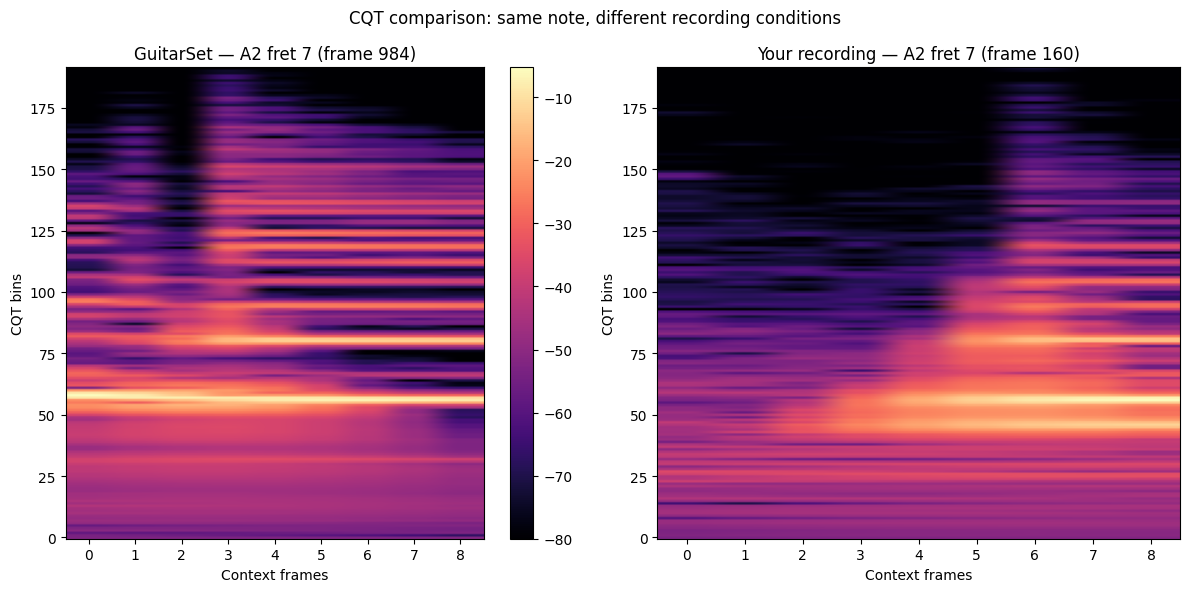

GuitarSet frame label:   [20  7  2 20 20 20]
Your recording label:    [20  7 20 20 20 20]


In [27]:
# Pick a note to compare — e.g. A2 fret 7 (string 1, fret 7)
target_string = 1  # A2
target_fret   = 7

# Find a matching frame in GuitarSet (from all_labels and all_windows)
guitarset_matches = np.where(all_labels[:, target_string] == target_fret)[0]
guitarset_frame_idx = guitarset_matches[0]  # take first match
guitarset_window = all_windows[guitarset_frame_idx]  # shape (192, 9)

# Find a matching frame in your recording (from windows and labels)
recording_matches = np.where(labels[:, target_string] == target_fret)[0]
recording_frame_idx = recording_matches[0]  # take first match
recording_window = windows[recording_frame_idx]  # shape (192, 9)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(guitarset_window, aspect='auto', origin='lower', cmap='magma')
axes[0].set_title(f'GuitarSet — A2 fret 7 (frame {guitarset_frame_idx})')
axes[0].set_xlabel('Context frames')
axes[0].set_ylabel('CQT bins')
axes[0].colorbar = plt.colorbar(axes[0].images[0], ax=axes[0])

axes[1].imshow(recording_window, aspect='auto', origin='lower', cmap='magma')
axes[1].set_title(f'Your recording — A2 fret 7 (frame {recording_frame_idx})')
axes[1].set_xlabel('Context frames')
axes[1].set_ylabel('CQT bins')

plt.suptitle('CQT comparison: same note, different recording conditions')
plt.tight_layout()
plt.show()

print(f"GuitarSet frame label:   {all_labels[guitarset_frame_idx]}")
print(f"Your recording label:    {labels[recording_frame_idx]}")